Shape: (2580, 7)
   Review #           Brand  \
0      2580       New Touch   
1      2579        Just Way   
2      2578          Nissin   
3      2577         Wei Lih   
4      2576  Ching's Secret   

                                             Variety Style Country Stars  \
0                          T's Restaurant Tantanmen    Cup   Japan  3.75   
1  Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...  Pack  Taiwan     1   
2                      Cup Noodles Chicken Vegetable   Cup     USA  2.25   
3                      GGE Ramen Snack Tomato Flavor  Pack  Taiwan  2.75   
4                                    Singapore Curry  Pack   India  3.75   

  Top Ten  
0     NaN  
1     NaN  
2     NaN  
3     NaN  
4     NaN  

Missing values:
 Review #       0
Brand          0
Variety        0
Style          2
Country        0
Stars          0
Top Ten     2539
dtype: int64

=== SUMMARY STATS ===
count    2573.00
mean        3.65
std         1.02
min         0.00
25%         3.25
50%      

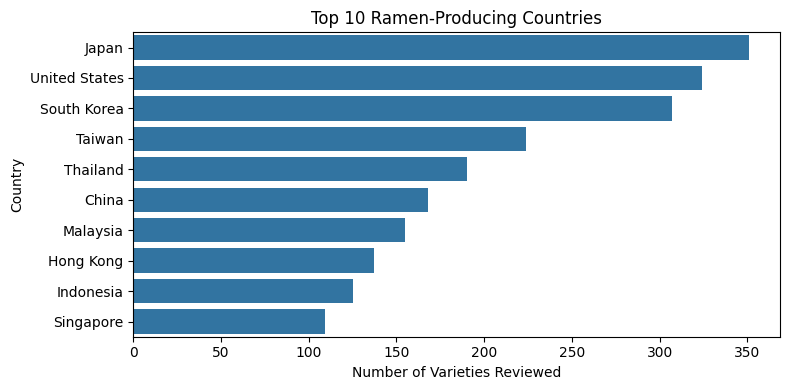

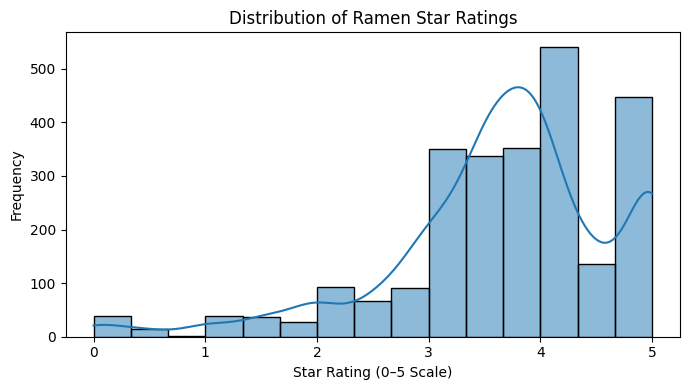

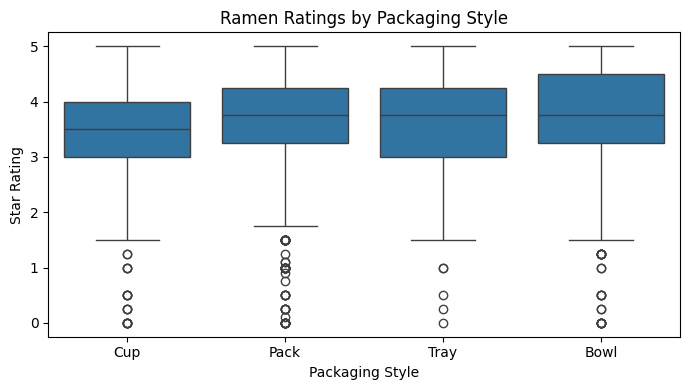


=== CONCLUSIONS ===
1. Cleaned dataset contains 2,573 rated ramen varieties across 37 countries.
2. Leading producers: Japan (351 reviews) and United States (324 reviews).
3. Overall average rating is 3.65 / 5.00 (median = 3.75).
4. Pack ramen dominates review volume and consistently scores higher than Cup or Bowl varieties.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------------
# 1. LOAD + INSPECT
# ---------------------------------------------------------------
df = pd.read_csv("ramen-ratings.csv")
print("Shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum())

# ---------------------------------------------------------------
# 2. CLEAN + PREPROCESS
# ---------------------------------------------------------------
# Remove 'Unrated' rows and convert Stars from text to numeric
df = df[df["Stars"] != "Unrated"].copy()
df["Stars"] = pd.to_numeric(df["Stars"])

# Standardize country names and fill missing Style values
df["Country"] = df["Country"].replace({"USA": "United States"})
df["Style"] = df["Style"].fillna("Unknown")

# Drop review ID column and duplicates
df = df.drop(columns=["Review #"]).drop_duplicates().reset_index(drop=True)

# Create rating tiers
df["Rating_Tier"] = pd.cut(
    df["Stars"],
    bins=[-0.1, 3.0, 4.0, 5.0],
    labels=["Low (0–3.0)", "Good (3.0–4.0)", "Top-Tier (4.0–5.0)"]
)

# ---------------------------------------------------------------
# 3. EDA
# ---------------------------------------------------------------
print("\n=== SUMMARY STATS ===")
print(df["Stars"].describe().round(2))

top_countries = df["Country"].value_counts().head(10)
top_brands = df["Brand"].value_counts().head(10)
style_avg = df.groupby("Style")["Stars"].agg(["count", "mean"]).sort_values("count", ascending=False)

print("\nTop 10 Countries:\n", top_countries)
print("\nTop 10 Brands:\n", top_brands)
print("\nAverage Rating by Packaging Style:\n", style_avg.round(2))

# ---------------------------------------------------------------
# 4. VISUALIZATIONS
# ---------------------------------------------------------------
# Plot 1: Top 10 Ramen-Producing Countries
plt.figure(figsize=(8, 4))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.xlabel("Number of Varieties Reviewed")
plt.ylabel("Country")
plt.title("Top 10 Ramen-Producing Countries")
plt.tight_layout()
plt.savefig("top_countries.png")
plt.show()

# Plot 2: Distribution of Star Ratings
plt.figure(figsize=(7, 4))
sns.histplot(df["Stars"], bins=15, kde=True)
plt.xlabel("Star Rating (0–5 Scale)")
plt.ylabel("Frequency")
plt.title("Distribution of Ramen Star Ratings")
plt.tight_layout()
plt.savefig("stars_distribution.png")
plt.show()

# Plot 3: Star Ratings by Packaging Style (Top 4 Styles)
top_styles = df["Style"].value_counts().head(4).index
plt.figure(figsize=(7, 4))
sns.boxplot(data=df[df["Style"].isin(top_styles)], x="Style", y="Stars")
plt.xlabel("Packaging Style")
plt.ylabel("Star Rating")
plt.title("Ramen Ratings by Packaging Style")
plt.tight_layout()
plt.savefig("stars_by_style.png")
plt.show()

# ---------------------------------------------------------------
# 5. CONCLUSIONS
# ---------------------------------------------------------------
print("\n=== CONCLUSIONS ===")
print(f"1. Cleaned dataset contains {len(df):,} rated ramen varieties across {df['Country'].nunique()} countries.")
print(f"2. Leading producers: {top_countries.index[0]} ({top_countries.iloc[0]} reviews) and {top_countries.index[1]} ({top_countries.iloc[1]} reviews).")
print(f"3. Overall average rating is {df['Stars'].mean():.2f} / 5.00 (median = {df['Stars'].median():.2f}).")
print(f"4. Pack ramen dominates review volume and consistently scores higher than Cup or Bowl varieties.")